# Élaboration d’un modèle de scoring pour "Prêt à dépenser" (1/2)

L’entreprise "**Prêt à dépenser**" propose des crédits à la consommation pour des personnes ayant peu ou pas d’historique de prêt.

L’entreprise souhaite mettre en œuvre un outil de “**scoring crédit**” pour calculer la probabilité qu’un client rembourse son crédit, puis classifie la demande en crédit accordé ou refusé.

Elle souhaite donc développer un **algorithme de classification** en s’appuyant sur des sources de données variées (données comportementales, données provenant d'autres institutions financières, etc.)



## 1. Imports

Les premiers imports sont plutôt typiques pour des projets de Machine Learning

In [59]:
# numpy et pandas pour la manipulation de données
import numpy as np
import pandas as pd

# Gestion du système de fichiers
import os

# Suppression des avertissements
import warnings
warnings.filterwarnings('ignore')

# Visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# # Métriques
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

## 2. Lecture des données

La première étape est de vérifier que tous les fichiers sources sont bien au bon endroit.

In [60]:
# Liste des fichiers sources disponibles
print(os.listdir("./input/"))

['application_test.csv', 'application_train.csv', 'app_test_enriched.parquet', 'app_train_enriched.parquet', 'bureau.csv', 'bureau_balance.csv', 'credit_card_balance.csv', 'HomeCredit_columns_description.csv', 'installments_payments.csv', 'POS_CASH_balance.csv', 'previous_application.csv', 'sample_submission.csv']


Maintenant nous allons créer un DataFrame contenant les données du fichier principal `application_train.csv`.

In [61]:
# Données d’apprentissage
app_train = pd.read_csv('./input/application_train.csv')
print(f"Dimensions des données d'apprentissage : {app_train.shape}")
print(f"Il y a {app_train.shape[0]} échantillons dans les données d'apprentissage.")
print(f"Il y a {app_train.shape[1]} variables (incluant la cible) dans les données d'apprentissage.")
app_train.head(10)

Dimensions des données d'apprentissage : (307511, 122)
Il y a 307511 échantillons dans les données d'apprentissage.
Il y a 122 variables (incluant la cible) dans les données d'apprentissage.


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
5,100008,0,Cash loans,M,N,Y,0,99000.0,490495.5,27517.5,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0
6,100009,0,Cash loans,F,Y,Y,1,171000.0,1560726.0,41301.0,...,0,0,0,0,0.0,0.0,0.0,1.0,1.0,2.0
7,100010,0,Cash loans,M,Y,Y,0,360000.0,1530000.0,42075.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
8,100011,0,Cash loans,F,N,Y,0,112500.0,1019610.0,33826.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
9,100012,0,Revolving loans,M,N,Y,0,135000.0,405000.0,20250.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


Créons également un DataFrame pour le deuxième fichier source principal `application_test.csv`.

In [62]:
# Données de test
app_test = pd.read_csv('./input/application_test.csv')
print(f"Dimensions des données de test : {app_test.shape}")
print(f"Il y a {app_test.shape[0]} échantillons dans les données de test.")
print(f"Il y a {app_test.shape[1]} variables dans les données de test.")
app_test.head()

Dimensions des données de test : (48744, 121)
Il y a 48744 échantillons dans les données de test.
Il y a 121 variables dans les données de test.


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [63]:
print(f"Il y a en tout {app_train.shape[0] + app_test.shape[0]} échantillons entre les données d'entrainement et de test.")
print(f"Le pourcentage d'échantillons dans le données de test est de {round((app_test.shape[0]/(app_train.shape[0] + app_test.shape[0])) * 100, 0)} % par rapport au nombre d'échantillons total.")

Il y a en tout 356255 échantillons entre les données d'entrainement et de test.
Le pourcentage d'échantillons dans le données de test est de 14.0 % par rapport au nombre d'échantillons total.


Créons des DataFrames pour tous les autres fichiers source.

In [64]:
# Données Bureau
bureau = pd.read_csv('./input/bureau.csv')
# Solde des crédits dans le Bureau du Crédit
bureau_balance = pd.read_csv('./input/bureau_balance.csv')
# Dossiers des demandes de prêts précédents
prev_app = pd.read_csv('./input/previous_application.csv')
# Solde mensuel des prêts précédents
pos_cash_bal = pd.read_csv('./input/POS_CASH_balance.csv')
# Données de paiement passés des crédits précédents
instal_pay = pd.read_csv('./input/installments_payments.csv')
# Solde mensuel des crédits de carte de crédit précédents
cred_card_bal = pd.read_csv('./input/credit_card_balance.csv')

## 3. Analyse exploratoire (Exploratory Data Analysis)

### 3.1. Distribution de la variable cible

Il est important, dans un premier temps de déterminer si la variable cible est équilibrée ou non

91.9 % des clients remboursent leur crédit.
Tandis que 8.1 % des client ne remboursent pas leur crédit


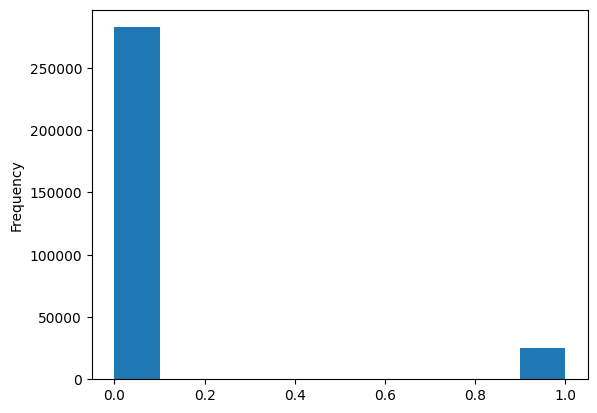

In [65]:
app_train['TARGET'].astype(int).plot.hist()
print(f"{round((((app_train['TARGET'] == 0).sum()) / app_train.shape[0]) * 100, 1)} % des clients remboursent leur crédit.")
print(f"Tandis que {round((((app_train['TARGET'] == 1).sum()) / app_train.shape[0]) * 100, 1)} % des client ne remboursent pas leur crédit")

On observe donc que nous faisons face à un problème de **déséquilibre des classes** qu’il faudra prendre en compte dans la suite du projet.

### 3.2. Analyse des valeurs manquantes

Les valeurs manquantes sont fréquentes dans les données de crédit, où certaines informations ne sont pas disponibles pour tous les demandeurs.

Avant de choisir une **stratégie d'imputation**, il est important de quantifier ces valeurs manquantes et d'observer si elles suivent un pattern (valeurs manquantes groupées sur les mêmes lignes, par exemple).

In [66]:
# Fonction permettant de calculer les valeurs manquantes par colonne
def missing_values_table(df):
    # Valeurs manquantes totales
    mis_val = df.isnull().sum()

    # Pourcentage de valeurs manquantes
    mis_val_percent = 100 * df.isnull().sum() / len(df)

    # Création d’un tableau avec les résultats
    mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)

    # Renommage des colonnes
    mis_val_table_ren_columns = mis_val_table.rename(
        columns = {0 : 'Valeurs manquantes', 1 : '% de toutes les valeurs'}
    )

    # Tri du tableau par pourcentage de données manquantes décroissant
    mis_val_table_ren_columns = mis_val_table_ren_columns[
        mis_val_table_ren_columns.iloc[:,1] != 0].sort_values(
            '% de toutes les valeurs', ascending=False).round(1)
    
    # Impression des informations récapitulatives
    print("Votre DataFrame sélectionné a " + str(df.shape[1]) + " colonnes.\n"
          "Il y a " + str(mis_val_table_ren_columns.shape[0]) + 
          " colonnes avec des valeurs manquantes.")
    
    # Renvoi du DataFrame avec les informations sur les valeurs manquantes
    return mis_val_table_ren_columns

In [67]:
# Statistiques des valeurs d’entraînement manquantes
missing_values_app_train = missing_values_table(app_train)
missing_values_app_train.head(20)

Votre DataFrame sélectionné a 122 colonnes.
Il y a 67 colonnes avec des valeurs manquantes.


,Valeurs manquantes,% de toutes les valeurs
COMMONAREA_MEDI,214865,69.9
COMMONAREA_MODE,214865,69.9
COMMONAREA_AVG,214865,69.9
NONLIVINGAPARTMENTS_MODE,213514,69.4
NONLIVINGAPARTMENTS_MEDI,213514,69.4
NONLIVINGAPARTMENTS_AVG,213514,69.4
FONDKAPREMONT_MODE,210295,68.4
LIVINGAPARTMENTS_AVG,210199,68.4
LIVINGAPARTMENTS_MEDI,210199,68.4
LIVINGAPARTMENTS_MODE,210199,68.4


In [68]:
# Statistiques des valeurs de test manquantes
missing_values_app_test = missing_values_table(app_test)
missing_values_app_test.head(20)

Votre DataFrame sélectionné a 121 colonnes.
Il y a 64 colonnes avec des valeurs manquantes.


,Valeurs manquantes,% de toutes les valeurs
COMMONAREA_AVG,33495,68.7
COMMONAREA_MODE,33495,68.7
COMMONAREA_MEDI,33495,68.7
NONLIVINGAPARTMENTS_AVG,33347,68.4
NONLIVINGAPARTMENTS_MODE,33347,68.4
NONLIVINGAPARTMENTS_MEDI,33347,68.4
FONDKAPREMONT_MODE,32797,67.3
LIVINGAPARTMENTS_MODE,32780,67.2
LIVINGAPARTMENTS_AVG,32780,67.2
LIVINGAPARTMENTS_MEDI,32780,67.2


Nous voyons qu’il y a de nombreuses colonnes qui ont beaucoup de valeurs manquantes.

Utilisons maintenant le package MissingNo pour avoir une vision plus graphique de ces valeurs manquantes.

Observons si les valeurs manquantes se trouvent au même endroit grâce à la méthode `matrix`.

<Axes: >

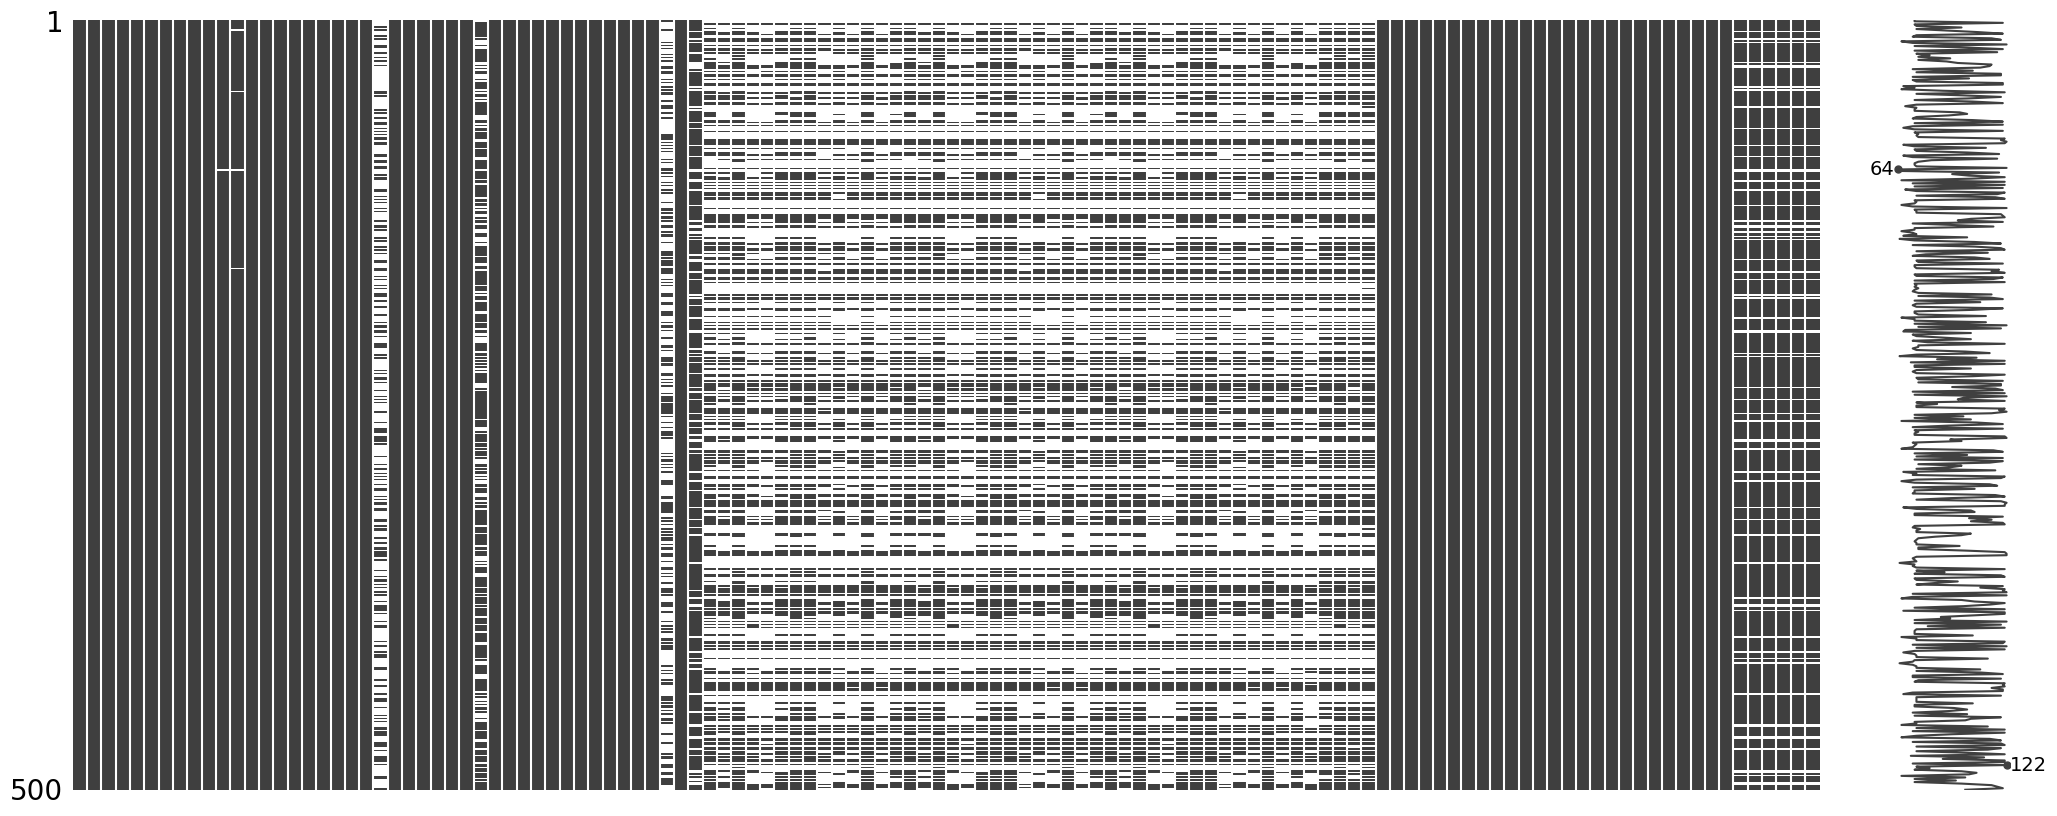

In [69]:
import missingno as msno
%matplotlib inline

msno.matrix(app_train.sample(500))

On remarque bien que sur les colonnes du milieu, les valeurs manquantes sont quasiment toujours au même endroit.

<Axes: >

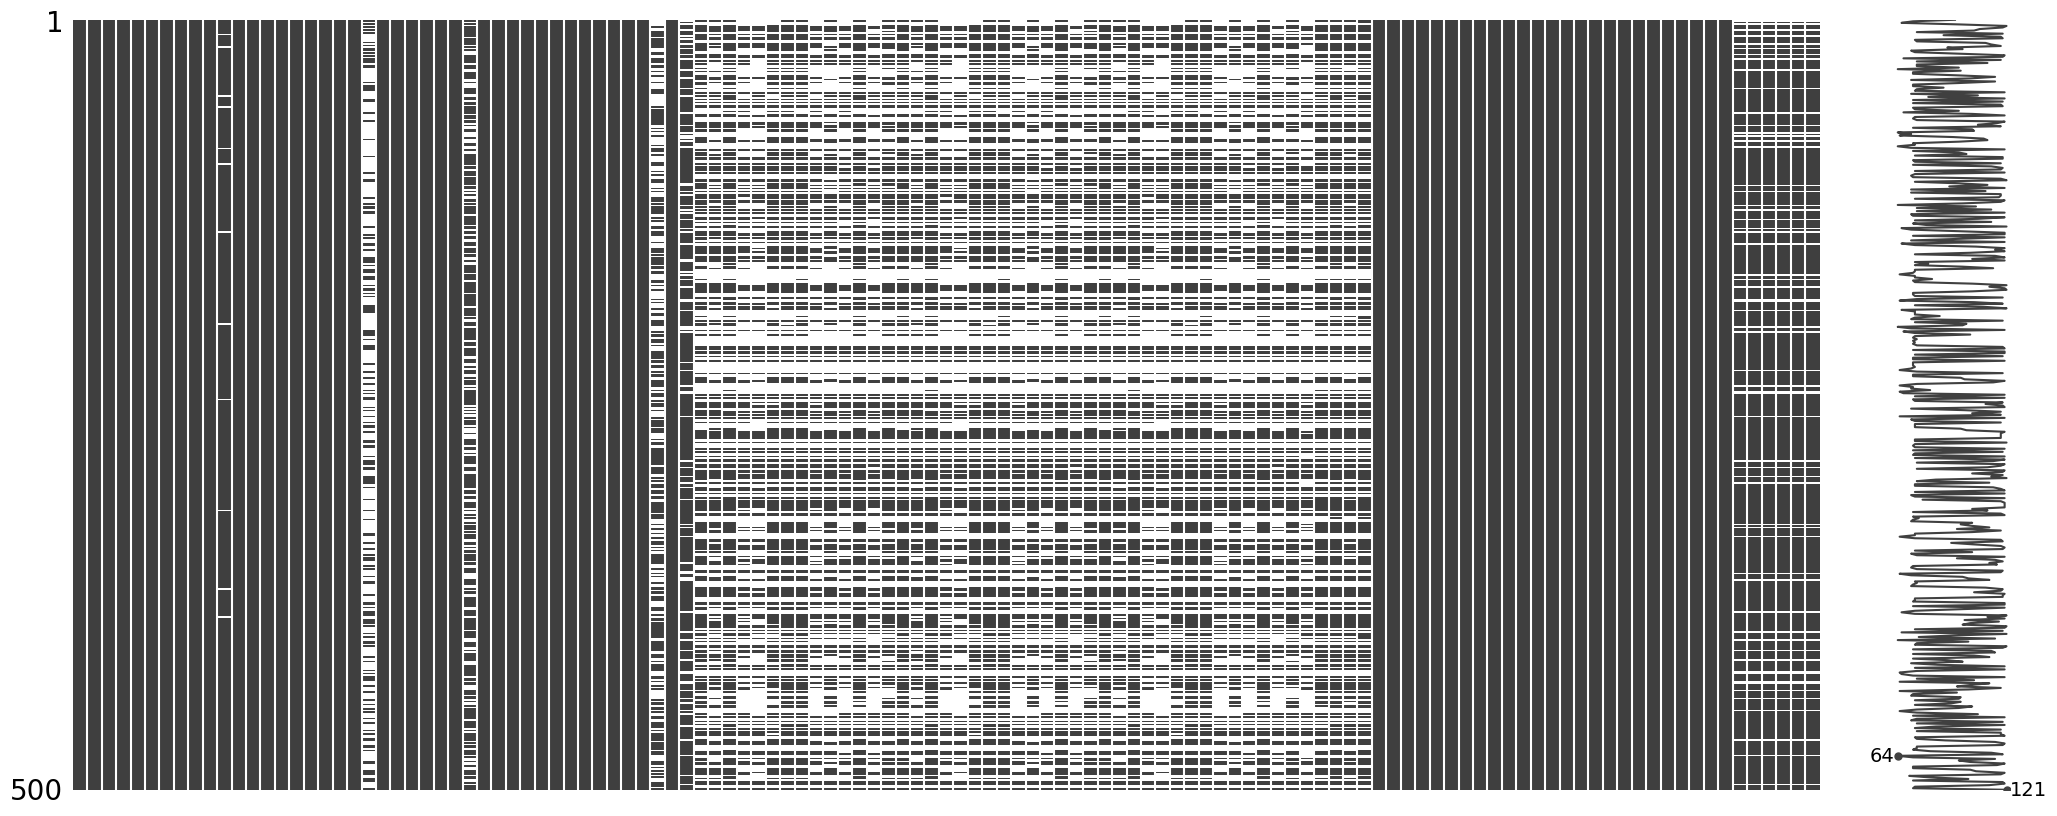

In [70]:
msno.matrix(app_test.sample(500))

On remarque le même phénomène dans les données de test.

### 3.3. Types de colonnes

Avant de passer à la modélisation, il est essentiel de distinguer les **variables numériques** des **variables catégorielles**, car elles ne seront pas traitées de la même manière.

Les variables catégorielles devront être encodées (Label Encoding ou One Hot Encoding) tandis que les variables numériques pourront être normalisées ou standardisées selon les besoins du modèle.

In [71]:
# Nombre de chaque type de colonne pour app_train
app_train.dtypes.value_counts()

float64    65
int64      41
object     16
Name: count, dtype: int64

In [72]:
# Nombre de chaque type de colonne pour app_test
app_test.dtypes.value_counts()

float64    65
int64      40
object     16
Name: count, dtype: int64

Les `float64` et les `int` représentent des valeurs numériques que nous ne devrons pas modifier (à part lors de la normalisation).

Regardons maintenant le nombre de valeurs distinctes pour chaque variable catégorielle `Object`.

In [73]:
# Nombre de classes uniques pour chaque variable catégorielle d’app_train
app_train.select_dtypes('object').apply(pd.Series.nunique, axis= 0)

NAME_CONTRACT_TYPE             2
CODE_GENDER                    3
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
NAME_TYPE_SUITE                7
NAME_INCOME_TYPE               8
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
OCCUPATION_TYPE               18
WEEKDAY_APPR_PROCESS_START     7
ORGANIZATION_TYPE             58
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
WALLSMATERIAL_MODE             7
EMERGENCYSTATE_MODE            2
dtype: int64

In [74]:
# Nombre de classes uniques pour chaque variable catégorielle d’app_test
app_test.select_dtypes('object').apply(pd.Series.nunique, axis= 0)

NAME_CONTRACT_TYPE             2
CODE_GENDER                    2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
NAME_TYPE_SUITE                7
NAME_INCOME_TYPE               7
NAME_EDUCATION_TYPE            5
NAME_FAMILY_STATUS             5
NAME_HOUSING_TYPE              6
OCCUPATION_TYPE               18
WEEKDAY_APPR_PROCESS_START     7
ORGANIZATION_TYPE             58
FONDKAPREMONT_MODE             4
HOUSETYPE_MODE                 3
WALLSMATERIAL_MODE             7
EMERGENCYSTATE_MODE            2
dtype: int64

La plupart des variables catégorielles ont un nombre relativement faible de valeurs uniques.

Concentrons nous sur le `CODE_GENDER` qui doit indiquer le genre du demandeur. Dans la liste ci-dessus, nous voyons qu’il y a 3 catégories. On peut imaginer qu’il y a des hommes, des femmes et des valeurs nulles.

Regardons la distribution des valeurs.

In [75]:
app_train['CODE_GENDER'].value_counts()

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

On voit qu’il n’y a que **4 lignes** de valeurs manquantes sur le genre du demandeur (sur les données d’entraînement) sur plus de 300 000.

On peut donc supprimer ces 4 lignes.

In [76]:
# Suppression des lignes dont la variable CODE_GENDER a pour valeur XNA
app_train = app_train[app_train['CODE_GENDER'] != 'XNA'].copy()

app_train['CODE_GENDER'].value_counts()

CODE_GENDER
F    202448
M    105059
Name: count, dtype: int64

Désormais, nous n’avons plus que 2 modalités pour le genre.

Pour les variables qui ont **deux** valeurs uniques ou moins, nous appliquerons un **Label Encoding**.

**ATTENTION** : Il faut faire le même encodage sur le DataFrame d’entraînement que sur le DataFrame de test pour retrouver la même logique.

In [77]:
# Prétraitement sklearn pour traiter les variables catégorielles
from sklearn.preprocessing import LabelEncoder

# Création d’un objet "Label Encoder"
le = LabelEncoder()
le_count = 0

# Parcours des colonnes
for col in app_train:
    if app_train[col].dtype == 'object':
        # Si 2 catégories uniques ou moins
        if len(list(app_train[col].unique())) <= 2:
            # S’entraîne sur les données d'entraînement
            le.fit(app_train[col])
            # Transforme à la fois les données d'entraînement et les données de test pour garantir le même encodage.
            app_train[col] = le.transform(app_train[col])
            app_test[col] = le.transform(app_test[col])
            
            # Garde une trace du nombre de colonnes qui ont été encodées par étiquette.
            le_count += 1
            
print('%d colonnes ont été encodées' % le_count)

4 colonnes ont été encodées


Pour les autres variables catégorielles, nous appliquerons un **One Hot Encoding**.

In [78]:
# One Hot Encoding des variables catégorielles
app_train = pd.get_dummies(app_train)
app_test = pd.get_dummies(app_test)

print("Dimensions du DataFrame d'entraînement :", app_train.shape)
print("Dimensions du DataFrame de test :", app_test.shape)

Dimensions du DataFrame d'entraînement : (307507, 241)
Dimensions du DataFrame de test : (48744, 238)


### 3.4. Alignement des données d’entraînement et de test

Pour aligner les données dans les deux DataFrames, il faut d’abord extraire l’information de la valeur cible dans une variable.

In [79]:
train_labels = app_train['TARGET']

Ensuite nous pouvons aligner les deux DataFrames

In [80]:
# Alignement des données d'entraînement et de test, ne conserve que les colonnes présentes dans les deux DataFrames
app_train, app_test = app_train.align(app_test, join = 'inner', axis = 1)

# Ajoute la cible à nouveau
app_train['TARGET'] = train_labels

print("Dimensions du DataFrame d'entraînement :", app_train.shape)
print("Dimensions du DataFrame de test :", app_test.shape)

Dimensions du DataFrame d'entraînement : (307507, 239)
Dimensions du DataFrame de test : (48744, 238)


### 3.5. Données aberrantes

Explorons maintenant les valeurs aberrantes qui peuvent s’être glissées dans les données.

#### 3.5.1. Âge

L’âge des demandeurs est exprimé en nombre de jours par rapport à la demande de prêt, et sont négatives.

Afin d’y voir plus clair nous pouvons les passer en années.

In [81]:
(app_train['DAYS_BIRTH'] / -365).describe()

count    307507.000000
mean         43.937061
std          11.956116
min          20.517808
25%          34.008219
50%          43.150685
75%          53.923288
max          69.120548
Name: DAYS_BIRTH, dtype: float64

In [82]:
(app_test['DAYS_BIRTH'] / -365).describe()

count    48744.000000
mean        44.022150
std         11.851782
min         20.104110
25%         34.235616
50%         43.246575
75%         53.800000
max         69.027397
Name: DAYS_BIRTH, dtype: float64

Ces âges semblent raisonnables. Il n'y a pas d'écarts significatifs, ni vers le haut ni vers le bas.

#### 3.5.2. Années travaillées

Maintenant, regardons le nombre d’années travaillées pour les demandeurs depuis leur demande de prêt.

In [83]:
(app_train['DAYS_EMPLOYED'] / -365).describe()

count    307507.000000
mean       -174.838162
std         387.058829
min       -1000.665753
25%           0.791781
50%           3.323288
75%           7.561644
max          49.073973
Name: DAYS_EMPLOYED, dtype: float64

In [84]:
(app_test['DAYS_EMPLOYED'] / -365).describe()

count    48744.000000
mean      -184.891415
std        395.475362
min      -1000.665753
25%          0.810959
50%          3.542466
75%          7.972603
max         47.843836
Name: DAYS_EMPLOYED, dtype: float64

Pour les données d’entraînement et de test on voit que la valeur min correspond à **-1000 ans**, ce qui est une valeur aberrante.

Le nombre de demandeurs avec cette valeur abérrante dans les données d'entraînement est de 55374.


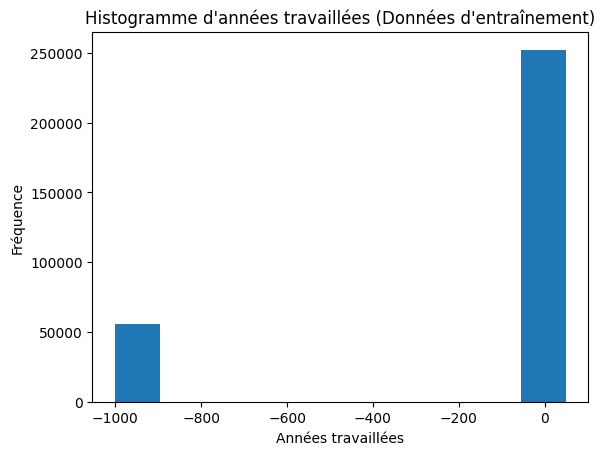

In [ ]:
(app_train['DAYS_EMPLOYED'] / -365).plot.hist(title = "Histogramme d'années travaillées (Données d'entraînement)")
plt.xlabel("Années travaillées")
plt.ylabel("Fréquence")

print(f"Le nombre de demandeurs avec cette valeur aberrante dans les données d'entraînement est de {(app_train['DAYS_EMPLOYED'] == 365243).sum()}.")

Le nombre de demandeurs avec cette valeur abérrante dans les données de test est de 9274.


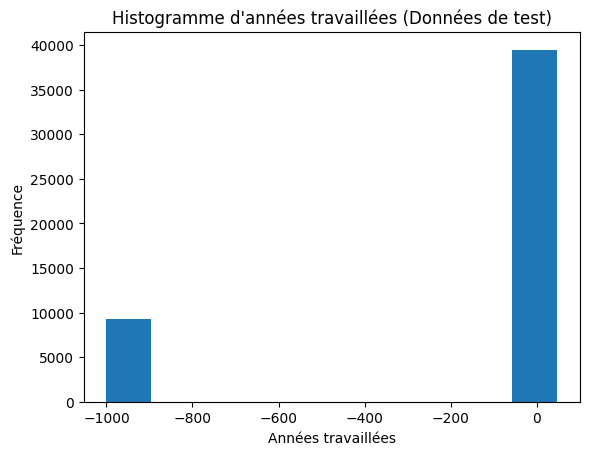

In [ ]:
(app_test['DAYS_EMPLOYED'] / -365).plot.hist(title = "Histogramme d'années travaillées (Données de test)")
plt.xlabel("Années travaillées")
plt.ylabel("Fréquence")

print(f"Le nombre de demandeurs avec cette valeur aberrante dans les données de test est de {(app_test['DAYS_EMPLOYED'] == 365243).sum()}.")

Le traitement des anomalies dépend de la situation exacte, il n'y a pas de règles fixes. L'une des approches les plus sûres consiste simplement à attribuer une valeur manquante aux anomalies, puis à les remplir (à l'aide de l'imputation) avant l'apprentissage automatique.

Dans ce cas, comme toutes les anomalies ont exactement la même valeur, nous voulons les remplir avec la même valeur au cas où tous ces prêts auraient quelque chose en commun.

Les valeurs anormales semblent avoir une certaine importance, nous voulons donc indiquer au modèle d'apprentissage automatique si nous avons effectivement complété ces valeurs.

Comme solution, nous allons compléter les valeurs anormales avec une valeur non numérique (np.nan), puis créer une nouvelle colonne booléenne indiquant si la valeur était anormale ou non.

Text(0, 0.5, 'Fréquence')

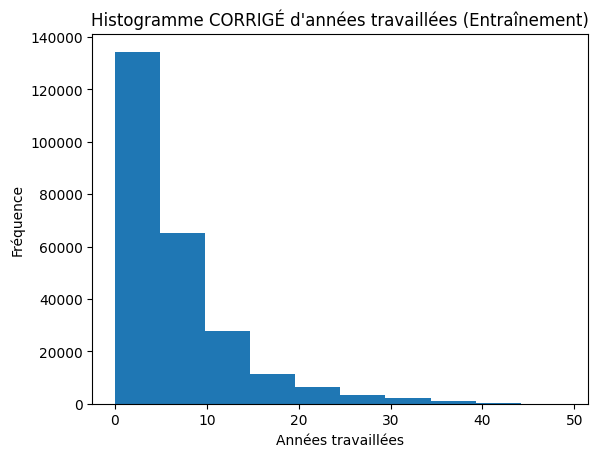

In [87]:
# Création d'une colonne d'indicateur d'aberration
app_train['DAYS_EMPLOYED_ANOM'] = app_train["DAYS_EMPLOYED"] == 365243

# Remplacement des valeurs aberrantes par "nan".
app_train['DAYS_EMPLOYED'].replace({365243: np.nan}, inplace = True)

(app_train['DAYS_EMPLOYED'] / -365).plot.hist(title = "Histogramme CORRIGÉ d'années travaillées (Entraînement)")
plt.xlabel('Années travaillées')
plt.ylabel("Fréquence")

Text(0, 0.5, 'Fréquence')

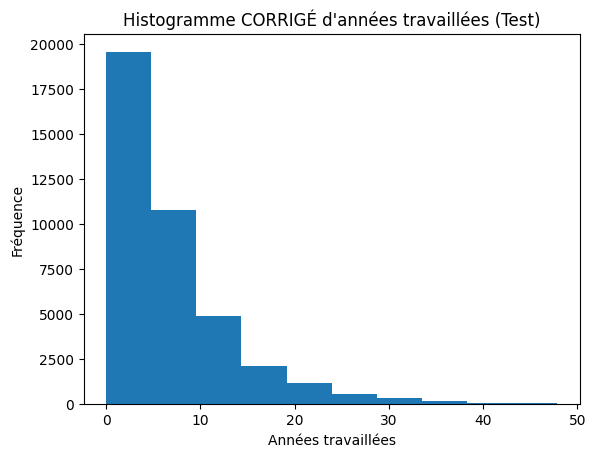

In [88]:
# Création d'une colonne d'indicateur d'aberration
app_test['DAYS_EMPLOYED_ANOM'] = app_test["DAYS_EMPLOYED"] == 365243

# Remplacement des valeurs aberrantes par "nan".
app_test['DAYS_EMPLOYED'].replace({365243: np.nan}, inplace = True)

(app_test['DAYS_EMPLOYED'] / -365).plot.hist(title = "Histogramme CORRIGÉ d'années travaillées (Test)")
plt.xlabel('Années travaillées')
plt.ylabel("Fréquence")

Les histogrammes semblent beaucoup plus réalistes maintenant que nous avons retiré la valeur aberrante des données (tout en gardant une trace de cette aberration pour la suite).

### 3.6 Analyse des corrélations (Pearson)

Il est bon de savoir quelles variables sont corrélées avec la cible. Nous allons donc calculer les corrélations de Pearson avec `TARGET`.

In [89]:
# Recherche des corrélations avec la cible et tri
correlations = app_train.corr()['TARGET'].sort_values()

# Affichage des corrélations
print('Corrélations les plus positives :\n', correlations.tail(15))
print('\nCorrélations les plus négatives :\n', correlations.head(15))

Corrélations les plus positives :
 OCCUPATION_TYPE_Laborers                             0.043017
FLAG_DOCUMENT_3                                      0.044341
REG_CITY_NOT_LIVE_CITY                               0.044394
FLAG_EMP_PHONE                                       0.045984
NAME_EDUCATION_TYPE_Secondary / secondary special    0.049822
REG_CITY_NOT_WORK_CITY                               0.050992
DAYS_ID_PUBLISH                                      0.051457
CODE_GENDER                                          0.054710
DAYS_LAST_PHONE_CHANGE                               0.055219
NAME_INCOME_TYPE_Working                             0.057483
REGION_RATING_CLIENT                                 0.058901
REGION_RATING_CLIENT_W_CITY                          0.060895
DAYS_EMPLOYED                                        0.074957
DAYS_BIRTH                                           0.078242
TARGET                                               1.000000
Name: TARGET, dtype: float64

Corré

On remarque que les corrélations les plus importantes sont l'âge (`DAYS_BIRTH`) et également les sources extérieures (`EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`).

Créons donc une heatmap sur ces quatre variables ainsi que sur la `TARGET`.

In [90]:
# Extraction des variables EXT_SOURCE et affichage des corrélations
ext_data = app_train[['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH']]
ext_data_corrs = ext_data.corr()
ext_data_corrs

,TARGET,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH
TARGET,1.000000,-0.155317,-0.160471,-0.178926,0.078242
EXT_SOURCE_1,-0.155317,1.000000,0.213982,0.186845,-0.600621
EXT_SOURCE_2,-0.160471,0.213982,1.000000,0.109182,-0.092009
EXT_SOURCE_3,-0.178926,0.186845,0.109182,1.000000,-0.205465
DAYS_BIRTH,0.078242,-0.600621,-0.092009,-0.205465,1.000000


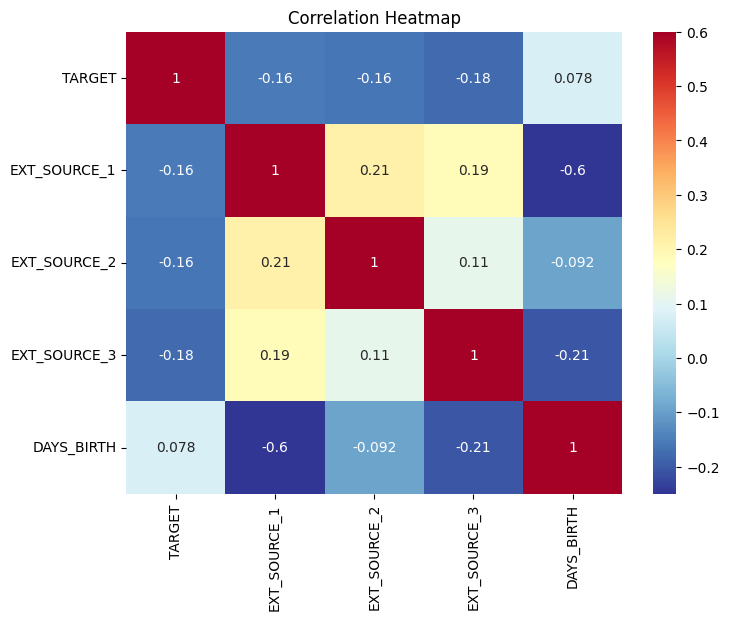

In [91]:
plt.figure(figsize = (8, 6))

# Heatmap des correlations
sns.heatmap(ext_data_corrs, cmap = plt.cm.RdYlBu_r, vmin = -0.25, annot = True, vmax = 0.6)
plt.title('Correlation Heatmap');

## 4. Entraînement & suivi d’un premier modèle Baseline

Même si tous les fichiers du projet ne sont pas encore agrégés, nous allons créer un premier modèle assez simple basé seulement sur le premier fichier d'entraînement, afin de créer un modèle simple qui nous donnera une première base à laquelle on pourra comparer les modèles suivants, plus élaborés mais plus complexes.

### 4.1. Définition des métriques importantes

Pour comparer les performances de notre modèle, il convient de les comparer entre eux au travers de métriques objectives et pertinentes par rapport au projet.

#### 4.1.1. Coût métier 

Michaël spécifie dans son email "que le coût d’un FN est dix fois supérieur au coût d’un FP".

C’est la métrique la plus importante.

On peut donc, à partir de ça, déterminer le **coût métier** avec la formule suivante :

`metier = (fn * 10) + (fp * 1)`

C’est une métrique qu’il faudra minimiser.

In [92]:
# Définition de la fonction de coût métier
def calcul_cout_metier(y_true, y_pred, cout_fn=10, cout_fp=1):
    """
    Calcule le coût financier des erreurs du modèle.
    Par défaut, on estime qu'un Faux Négatif (défaut de paiement non détecté) 
    coûte 10 fois plus cher qu'un Faux Positif (client légitime refusé).
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    metier = (fn * cout_fn) + (fp * cout_fp)
    return metier

#### 4.1.2. AUC (Area Under the Curve)

Le Score **AUC** (Area Under the Curve) est une mesure de performance utilisée pour évaluer la qualité globale d'un modèle de classification.

Son calcul fournit une indication quantitative de la capacité du modèle à classer correctement les exemples positifs et négatifs.

#### 4.1.3. Accuracy

Le score d’**Accuracy** représente la mesure de performance la plus intuitive dans la classification par apprentissage automatique. Il s'agit du pourcentage de prédictions correctes réalisées par un modèle par rapport au nombre total de prédictions.

`accuracy = (tp + tn) / (tn + fp + fn + tp)`

#### 4.1.4. Rappel

Le **recall** (ou rappel en français) permet de savoir le pourcentage de positifs bien prédit par notre modèle.

En d’autres termes c’est le nombre de positifs bien prédit (Vrai Positif) divisé par l’ensemble des positifs (Vrai Positif + Faux Négatif).

`recall = tp / (tp + fn)`

#### 4.1.5. F1 Score

Le **score F1** est la moyenne harmonique de la précision et du rappel, offrant une mesure équilibrée qui tient compte des faux positifs et des faux négatifs.

Elle est particulièrement utile pour gérer des ensembles de données déséquilibrés.

`f1_score = (precision * recall) / (precision + recall)`

### 4.2. Création d’un premier Run sur MLflow

Comme nous l'avons vu précédemment, les variables contiennent de nombreuses valeurs manquantes qu'il faudra imputer.

Pour cela, nous allons créer un `Pipeline` Scikit-Learn.

**ATTENTION** : il faut démarrer le serveur (avec : `mlflow server --port 5000`) avant d’exécuter les cellules suivantes.

In [ ]:
# --- Imports nécessaires ---
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# --- Préparation des données ---
# Sépare la variable cible (TARGET) des features
y = app_train['TARGET']
X = app_train.drop(columns=['TARGET'])

# Divise tes données en jeu d'entraînement et jeu de validation (ex: 80% train, 20% validation)
X_train, X_test, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# --- Définition du Pipeline ---
pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),               # Met à l'échelle les données
    ('classifier', LogisticRegression(C=0.0001, class_weight='balanced', random_state=42))
])

# --- Configuration de MLflow ---
# Connecte le notebook au serveur local
mlflow.set_tracking_uri("http://127.0.0.1:5000")
# Donne un nom clair à l’expérience
mlflow.set_experiment("Projet6_Scoring_Credit")

# --- Entraînement et Tracking ---
# On ouvre le contexte MLflow
with mlflow.start_run(run_name="Logistic_Regression_Baseline"):
    
    # Entraînement du modèle
    print("Entraînement en cours...")
    pipeline.fit(X_train, y_train)
    
    # Prédictions sur le jeu de validation (on utilise predict_proba pour l'AUC et predict pour les autres métriques)
    # [:, 1] permet de récupérer uniquement les probabilités de la classe 1 (défaut de paiement)
    y_pred_proba = pipeline.predict_proba(X_test)[:, 1]
    y_pred = pipeline.predict(X_test)
    
    # Calcul des métriques
    auc_score = roc_auc_score(y_val, y_pred_proba)
    accuracy = accuracy_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    metier = calcul_cout_metier(y_val, y_pred)
    print(f"Métriques : Coût métier: {metier:.4f} | Accuracy: {accuracy:.4f} | AUC: {auc_score:.4f}")
    
    # Enregistrement (Logging) dans MLflow
    # On loggue les paramètres importants
    mlflow.log_param("model_type", "Logistic Regression")
    mlflow.log_param("scaler", "MinMaxScaler")
    mlflow.log_param("imputer_strategy", pipeline.named_steps['imputer'].strategy)
    mlflow.log_param("C", pipeline.named_steps['classifier'].C)
    mlflow.log_param("random_state", pipeline.named_steps['classifier'].random_state)
    mlflow.log_param("class_weight", pipeline.named_steps['classifier'].class_weight)
    mlflow.log_param("n_features", X_train.shape[1]) # Le nombre de colonnes utilisées
    mlflow.log_param("step", 0)
    
    # On loggue les métriques de performance
    mlflow.log_metric("auc_score", auc_score)
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)
    mlflow.log_metric("cout_metier", metier)

    # Inférence de la signature du modèle
    signature = infer_signature(X_test, y_pred)
    
    # On sauvegarde le modèle complet (le pipeline)
    mlflow.sklearn.log_model(
        sk_model=pipeline,
        artifact_path="baseline_model",
        signature=signature,
        registered_model_name="Credit_Scoring_Model"
    )

    # On sauvegarde les tags
    mlflow.set_tag("Type_modele", "baseline")
    mlflow.set_tag("features", "application_train_only")
    mlflow.set_tag("statut", "developpement")
    # La balise exacte reconnue par l'UI MLflow pour les commentaires
    mlflow.set_tag("mlflow.note.content", "Run initial (baseline) : Régression logistique simple. Données brutes sans feature engineering. Objectif : obtenir un score de référence.")
    
    print("Run MLflow enregistré avec succès !")

Entraînement en cours...
Métriques : Coût métier: 36561.0000 | Accuracy: 0.6518 | AUC: 0.7159


2026/02/27 20:01:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/02/27 20:01:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/02/27 20:01:44 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/02/27 20:01:45 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 29
Created version '29' of model 'Credit_Sco

Run MLflow enregistré avec succès !
🏃 View run Logistic_Regression_Baseline at: http://127.0.0.1:5000/#/experiments/3/runs/460cc75510c9461f850de1b27f06650d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Voici ce que ça donne dans l’UI de MLflow :

![Image de l’UI avec le premier run](./images/baseline_ui.png "Premier run de baseline sur mlflow UI.")

Comme on peut le voir, les informations suivante ont bien été enregistrées :
* Le nom du Run
* La description
* Les métriques (AUC, accuracy, recall, f1_score et le cout métier)
* Les paramètres importants du modèle
* Le modèle est enregistré

## 5. Comparaison des modèles

Maintenant que nous avons eu notre premier run avec notre `Baseline`, il pourrait être intéressant de refactoriser le code en différentes fonctions afin de pouvoir réutiliser ces fonctions plus tard pour comparer différents modèles entre eux.

### 5.1 Création des fonctions

Nous allons donc créer les fonctions indispensables.

Comme notre dataset est fortement déséquilibré, il convient de faire une stratification des données avec `StratifiedKFold`.

In [ ]:
from sklearn.model_selection import StratifiedKFold

def train_and_log_model(pipeline, X, y, experiment_name, run_name, tags_dict, step, n_splits=5):
    """
    Entraîne un modèle avec StratifiedKFold et logue tout dans MLflow.
    """
    mlflow.set_experiment(experiment_name)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    # Listes pour stocker les métriques de chaque fold
    auc_scores, accuracy_scores, recall_scores, f1_scores, cout_metier_scores = [], [], [], [], []
    
    with mlflow.start_run(run_name=run_name):
        for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
            # Split
            X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
            y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
            
            # Entraînement
            pipeline.fit(X_train, y_train)
            
            # Prédictions
            y_pred = pipeline.predict(X_val)
            y_pred_proba = pipeline.predict_proba(X_val)[:, 1]
            
            # Métriques du fold
            auc_scores.append(roc_auc_score(y_val, y_pred_proba))
            accuracy_scores.append(accuracy_score(y_val, y_pred))
            recall_scores.append(recall_score(y_val, y_pred))
            f1_scores.append(f1_score(y_val, y_pred))
            cout_metier_scores.append(calcul_cout_metier(y_val, y_pred))

            # Print du fold
            print(f"Fold {fold+1}/{n_splits} - Coût métier : {cout_metier_scores[-1]:.4f}")
        
        # Logging des moyennes ET des écarts-types
        mlflow.log_metric("auc_mean", np.mean(auc_scores))
        mlflow.log_metric("auc_std", np.std(auc_scores))
        mlflow.log_metric("acc_mean", np.mean(accuracy_scores))
        mlflow.log_metric("acc_std", np.std(accuracy_scores))
        mlflow.log_metric("rec_mean", np.mean(recall_scores))
        mlflow.log_metric("rec_std", np.std(recall_scores))
        mlflow.log_metric("f1_mean", np.mean(f1_scores))
        mlflow.log_metric("f1_std", np.std(f1_scores))
        mlflow.log_metric("met_mean", np.mean(cout_metier_scores))
        mlflow.log_metric("met_std", np.std(cout_metier_scores))
        
        # Logging des tags (commentaires, modèle)
        for key, value in tags_dict.items():
            mlflow.set_tag(key, value)
        
        # Ré-entraînement sur l'ensemble des données
        pipeline.fit(X, y)

        # Logging automatique des paramètres du pipeline
        params = extract_pipeline_params(pipeline)
        for key, value in params.items():
            mlflow.log_param(key, value)
        mlflow.log_param("step", step)

        # Sauvegarde du modèle
        signature = infer_signature(X, pipeline.predict(X))
        mlflow.sklearn.log_model(
            sk_model=pipeline,
            artifact_path="model",
            signature=signature,
            registered_model_name="Credit_Scoring_Model"
        )
        
        print(f"Run '{run_name}' terminé — Coût métier : {np.mean(cout_metier_scores):.4f} (±{np.std(cout_metier_scores):.4f})")


def extract_pipeline_params(pipeline):
    """Extrait les paramètres utiles du pipeline pour MLflow."""
    params = {}
    for name, step in pipeline.named_steps.items():
        step_params = step.get_params()
        for param_name, param_value in step_params.items():
            # Filtre les types compatibles avec MLflow
            if isinstance(param_value, (str, int, float, bool)) or param_value is None:
                params[f"{name}__{param_name}"] = param_value
    return params

### 5.2. Comparaison de modèles simples

#### 5.2.1. Régression linéaire

Testons nos fonctions avec notre code refactorisé sur la régression linéaire.

In [ ]:
# --- Régression Logistique ---
# création du Pipeline
pipeline_lr = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LogisticRegression(C=0.0001, class_weight='balanced', random_state=42))
])

# Appel de la fonction
train_and_log_model(pipeline_lr, X, y,
                    experiment_name="Projet6_Scoring_Credit",
                    run_name="LogisticRegression_CV",
                    tags_dict={"Type_modele": "baseline", "features": "application_train_only", "status": "developpement", "mlflow.note.content": "Run (baseline) : Régression logistique simple avec stratification"},
                    step=1)

Fold 1/5 - Coût métier : 37356.0000
Fold 2/5 - Coût métier : 36355.0000
Fold 3/5 - Coût métier : 37038.0000
Fold 4/5 - Coût métier : 36322.0000
Fold 5/5 - Coût métier : 36630.0000


2026/02/27 20:02:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/02/27 20:02:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/02/27 20:02:59 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/02/27 20:02:59 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 30


Run 'LogisticRegression_CV' terminé — Coût métier : 36740.2000 (±400.8263)
🏃 View run LogisticRegression_CV at: http://127.0.0.1:5000/#/experiments/3/runs/424ecf5b95704dd1aece0da368dc9ef2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Created version '30' of model 'Credit_Scoring_Model'.


#### 5.2.2. Random Forest

Maintenant passons avec un modèle d'ensemble simple, comme le Random Forest.

In [ ]:
# Lancé une fois mais score métier médiocre (49 568)

# --- Random Forest ---
#from sklearn.ensemble import RandomForestClassifier

# création du Pipeline
#pipeline_rf = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),
#    ('scaler', MinMaxScaler()), # Optionnel pour les arbres, conservé pour la cohérence des pipelines
#    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1))
#])

# Appel de la fonction
#train_and_log_model(pipeline_rf, X, y,
#                    experiment_name="Projet6_Scoring_Credit",
#                    run_name="RandomForestClassifier_CV",
#                    tags_dict={"Type_modele": "ensemble", "features": "application_train_only", "status": "developpement", "mlflow.note.content": "Run comparaison de modèles : Random Forest simple avec stratification"},
#                    step=1)

Fold 1/5 - Coût métier : 49575.0000
Fold 2/5 - Coût métier : 49554.0000
Fold 3/5 - Coût métier : 49563.0000
Fold 4/5 - Coût métier : 49576.0000
Fold 5/5 - Coût métier : 49572.0000


2026/02/27 20:05:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/02/27 20:05:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/02/27 20:05:20 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/02/27 20:07:11 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 31
Created version '31' of model 'Credit_Sco

Run 'RandomForestClassifier_CV' terminé — Coût métier : 49568.0000 (±8.3666)
🏃 View run RandomForestClassifier_CV at: http://127.0.0.1:5000/#/experiments/3/runs/f1f0095614eb40568276871689bbcdc8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


### 5.3. Comparaison des modèles plus puissants

#### 5.3.1. XGBoost

XGBoost gère le déséquilibre des classes différemment : au lieu de `class_weight='balanced'`, il utilise le paramètre `scale_pos_weight`.

L'idée est de lui donner le ratio entre la classe majoritaire et la classe minoritaire.

Dans ce projet c’est environ 92%/8%, donc un ratio aux alentours de 11.

In [ ]:
# --- XGBoost ---
from xgboost import XGBClassifier

# Calcul du ratio de déséquilibre
scale_pos = (y == 0).sum() / (y == 1).sum()

pipeline_xgb = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', XGBClassifier(
        n_estimators=100,
        scale_pos_weight=scale_pos,
        eval_metric='auc',
        random_state=42,
        n_jobs=-1
    ))
])

train_and_log_model(pipeline_xgb, X, y,
                    experiment_name="Projet6_Scoring_Credit",
                    run_name="XGBClassifier_CV",
                    tags_dict={"Type_modele": "boosting", "features": "application_train_only", 
                               "status": "developpement", 
                               "mlflow.note.content": "XGBoost avec scale_pos_weight pour gestion du déséquilibre"},
                               step=1)

Fold 1/5 - Coût métier : 33892.0000
Fold 2/5 - Coût métier : 33738.0000
Fold 3/5 - Coût métier : 33430.0000
Fold 4/5 - Coût métier : 33537.0000
Fold 5/5 - Coût métier : 33933.0000


2026/02/27 20:08:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/02/27 20:08:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/02/27 20:08:35 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/02/27 20:08:36 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 32


Run 'XGBClassifier_CV' terminé — Coût métier : 33706.0000 (±195.9010)
🏃 View run XGBClassifier_CV at: http://127.0.0.1:5000/#/experiments/3/runs/88b5b01c3c1443d1a521507234997226
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Created version '32' of model 'Credit_Scoring_Model'.


#### 5.3.2. LightGBM

LightGBM est souvent plus rapide que XGBoost sur de gros datasets comme ici.

Il propose directement un paramètre `is_unbalance=True` qui fait le travail automatiquement.

In [ ]:
# --- LightGBM ---
from lightgbm import LGBMClassifier

pipeline_lgbm = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler()),
    ('classifier', LGBMClassifier(
        n_estimators=100,
        is_unbalance=True,
        random_state=42,
        n_jobs=-1,
        verbose=-1  # Supprime les logs d'entraînement qui sont très verbeux
    ))
])

train_and_log_model(pipeline_lgbm, X, y,
                    experiment_name="Projet6_Scoring_Credit",
                    run_name="LGBMClassifier_CV",
                    tags_dict={"Type_modele": "boosting", "features": "application_train_only",
                               "status": "developpement",
                               "mlflow.note.content": "LightGBM avec is_unbalance pour gestion du déséquilibre"},
                    step=1)

Fold 1/5 - Coût métier : 33090.0000
Fold 2/5 - Coût métier : 32365.0000
Fold 3/5 - Coût métier : 33015.0000
Fold 4/5 - Coût métier : 32574.0000
Fold 5/5 - Coût métier : 33366.0000


2026/02/27 20:09:51 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/02/27 20:09:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/02/27 20:09:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/02/27 20:09:55 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 33
Created version '33' of model 'Credit_Sco

Run 'LGBMClassifier_CV' terminé — Coût métier : 32882.0000 (±362.5912)
🏃 View run LGBMClassifier_CV at: http://127.0.0.1:5000/#/experiments/3/runs/6b865254aaed4adab3e5d603808d697b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


#### 5.3.3. MLP (réseau de neurones)

Pour le MLP, le scaler est cette fois **indispensable**, les réseaux de neurones y sont très sensibles.

Et comme il n'y a pas de `class_weight` natif dans `MLPClassifier`, on garde le `MinMaxScaler` et on pourra éventuellement gérer le déséquilibre via SMOTE plus tard ou en ajustant le seuil de décision.

In [ ]:
# MLP lancé une fois, mais ça a pris 4h48. Le score métier est mauvais (47 148)

# --- MLP ---
#from sklearn.neural_network import MLPClassifier

#pipeline_mlp = Pipeline(steps=[
#    ('imputer', SimpleImputer(strategy='median')),
#    ('scaler', MinMaxScaler()),  # Indispensable pour les réseaux de neurones
#    ('classifier', MLPClassifier(
#        hidden_layer_sizes=(100, 50),
#        max_iter=200,
#        random_state=42
#    ))
#])

#train_and_log_model(pipeline_mlp, X, y,
#                    experiment_name="Projet6_Scoring_Credit",
#                    run_name="MLPClassifier_CV",
#                    tags_dict={"Type_modele": "neural_network", "features": "application_train_only",
#                               "status": "developpement",
#                               "mlflow.note.content": "MLP (100,50) - pas de gestion native du déséquilibre"},
#                    step=1)

Fold 1/5 - Coût métier : 47127.0000
Fold 2/5 - Coût métier : 47512.0000
Fold 3/5 - Coût métier : 46866.0000
Fold 4/5 - Coût métier : 47462.0000
Fold 5/5 - Coût métier : 46774.0000


2026/02/28 01:03:55 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/02/28 01:03:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/02/28 01:03:59 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
Registered model 'Credit_Scoring_Model' already exists. Creating a new version of this model...
2026/02/28 01:03:59 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Credit_Scoring_Model, version 34
Created version '34' of model 'Credit_Sco

Run 'MLPClassifier_CV' terminé — Coût métier : 47148.2000 (±300.3108)
🏃 View run MLPClassifier_CV at: http://127.0.0.1:5000/#/experiments/3/runs/3bafa7edfd1c487592060e8b8895f12f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


### Analyse de la comparaison des modèles

Après avoir codé une fonction réutilisable, nous avons pu comparer 5 modèles sur un jeu d’entraînement relativement réduit.

Nous déterminé un coût métier qui va être la métrique principale pour classer nos modèles.

Les résultats sont les suivants :
1. **LightGBM** avec un coût métier moyen de **32 882** (meilleur)
2. **XGBoost** avec un coût métier moyen de 33 706
3. **Régression logistique** avec un coût métier moyen de 36 740
4. **MLP** avec un coût métier moyen de 47 148
5. **Random Forest** avec un coût métier moyen de 49 568

**IMPORTANT** : Il faut souligner que cette comparaison est faite sur des modèles non-optimisés, avec un jeu de données réduit et un seuil non optimal.

Même si les performances des modèles vont sûrement varier une fois ces ajouts faits, il est résonnable de se débarasser des deux derniers modèles dont le retard est vraiment important.

Ainsi, les modèles sélectionné pour la suite sont :
* **LightGBM** - champion actuel, à optimiser en priorité
* **XGBoost** - très proche, bon challenger pour valider que cette sélection est robuste
* **Régression logistique** - servira de baseline interprétable.

## 6. Enrichissement des données

Maintenant que nous avons comparé différents modèles sur le fichier principal, nous allons ajouter les données des fichiers auxiliaires.

### 6.1. `bureau` et `bureau_balance`

Commençons par `bureau` et `bureau_balance` qui sont les tables les plus intuitives.

Comme les tables annexes contiennent **plusieurs lignes par client** (un client peut avoir eu plusieurs crédits passés, plusieurs mensualités, etc.), on va suivre la logique suivante :
1. Agrégation de `bureau_balance` grâce à la clé `SK_ID_BUREAU`.
2. Jointure de l’agrégation avec `bureau`.
3. Agrégation de `bureau` grâce à la clé `SK_ID_CURR`
4. Jointure de l’agrégation finale avec `app_train` et `app_test`

Tout d’abord regardons les deux tables `bureau` et `bureau_balance`.

In [100]:
print("=== BUREAU ===")
print(f"Shape: {bureau.shape}")
print(f"Colonnes: {bureau.columns.tolist()}")
print(f"\nClients uniques: {bureau['SK_ID_CURR'].nunique()}")
print(f"Crédits uniques: {bureau['SK_ID_BUREAU'].nunique()}")
print(f"\nTypes de crédit:\n{bureau['CREDIT_TYPE'].value_counts().head(10)}")

print("\n\n=== BUREAU_BALANCE ===")
print(f"Shape: {bureau_balance.shape}")
print(f"Colonnes: {bureau_balance.columns.tolist()}")
print(f"\nStatuts:\n{bureau_balance['STATUS'].value_counts()}")

=== BUREAU ===
Shape: (1716428, 17)
Colonnes: ['SK_ID_CURR', 'SK_ID_BUREAU', 'CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'DAYS_CREDIT', 'CREDIT_DAY_OVERDUE', 'DAYS_CREDIT_ENDDATE', 'DAYS_ENDDATE_FACT', 'AMT_CREDIT_MAX_OVERDUE', 'CNT_CREDIT_PROLONG', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT', 'AMT_CREDIT_SUM_LIMIT', 'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_TYPE', 'DAYS_CREDIT_UPDATE', 'AMT_ANNUITY']

Clients uniques: 305811
Crédits uniques: 1716428

Types de crédit:
CREDIT_TYPE
Consumer credit                           1251615
Credit card                                402195
Car loan                                    27690
Mortgage                                    18391
Microloan                                   12413
Loan for business development                1975
Another type of loan                         1017
Unknown type of loan                          555
Loan for working capital replenishment        469
Cash loan (non-earmarked)                      56
Name: count, dtype: int64


=== BUR

On a une bonne vue d'ensemble. Quelques observations importantes :
* **1,7 millions de lignes** dans `bureau` pour ~306 000 clients → en moyenne ~5,6 crédits par client
* **27 millions de lignes** dans `bureau_balance` → c'est la plus grosse table, d'où l'importance d'agréger bureau_balance en premier
* `STATUS` : les valeurs de 0 à 5 représentent les jours de retard de paiement (0 = pas de retard, 1 = 1-30 jours, etc.), C = clôturé, X = inconnu — c'est une info très riche pour prédire le défaut.

Commençons par l’agrégation de `bureau_balance`.

In [101]:
def aggregate_bureau_balance(bureau_balance):
    """
    Agrège bureau_balance au niveau de chaque crédit (SK_ID_BUREAU).
    On résume l'historique mensuel de chaque crédit en quelques indicateurs.
    """
    # One-hot encoding de STATUS (C, X, 0, 1, 2, 3, 4, 5)
    bb = pd.get_dummies(bureau_balance, columns=['STATUS'], prefix='BB_STATUS')
    
    # Agrégation par crédit (SK_ID_BUREAU)
    # - MONTHS_BALANCE : min (= mois le plus ancien), max, taille (= durée de l'historique)
    # - Colonnes STATUS one-hot : moyenne (= proportion de chaque statut)
    bb_agg = bb.groupby('SK_ID_BUREAU').agg(
        # Profondeur de l'historique
        BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),
        BB_MONTHS_MAX=('MONTHS_BALANCE', 'max'),
        BB_MONTHS_COUNT=('MONTHS_BALANCE', 'size'),
    )
    
    # Moyennes des colonnes STATUS one-hot (proportion de mois dans chaque statut)
    status_cols = [col for col in bb.columns if col.startswith('BB_STATUS_')]
    status_means = bb.groupby('SK_ID_BUREAU')[status_cols].mean()
    
    # Concaténation
    bb_agg = bb_agg.join(status_means)
    
    print(f"bureau_balance agrégé : {bb_agg.shape}")
    return bb_agg

In [102]:
bb_agg = aggregate_bureau_balance(bureau_balance)
bb_agg.head()

bureau_balance agrégé : (817395, 11)


,BB_MONTHS_MIN,BB_MONTHS_MAX,BB_MONTHS_COUNT,BB_STATUS_0,BB_STATUS_1,BB_STATUS_2,BB_STATUS_3,BB_STATUS_4,BB_STATUS_5,BB_STATUS_C,BB_STATUS_X
SK_ID_BUREAU,,,,,,,,,,,
5001709,-96,0,97,0.000000,0.0,0.0,0.0,0.0,0.0,0.886598,0.113402
5001710,-82,0,83,0.060241,0.0,0.0,0.0,0.0,0.0,0.578313,0.361446
5001711,-3,0,4,0.750000,0.0,0.0,0.0,0.0,0.0,0.000000,0.250000
5001712,-18,0,19,0.526316,0.0,0.0,0.0,0.0,0.0,0.473684,0.000000
5001713,-21,0,22,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,1.000000


Continuons en joignant `bb_agg` à `bureau`.

In [103]:
def aggregate_bureau(bureau, bb_agg):
    """
    Enrichit bureau avec les agrégats de bureau_balance,
    puis agrège le tout au niveau client (SK_ID_CURR).
    """
    # --- Étape 1 : Jointure bureau + bb_agg ---
    bureau = bureau.join(bb_agg, on='SK_ID_BUREAU', how='left')
    bureau.drop(columns='SK_ID_BUREAU', inplace=True)
    
    # --- Étape 2 : One-hot encoding des cvariables atégorielles de bureau ---
    cat_cols = bureau.select_dtypes('object').columns.tolist()
    print(f"Colonnes catégorielles encodées : {cat_cols}")
    bureau = pd.get_dummies(bureau, columns=cat_cols)
    
    # --- Étape 3 : Agrégation par client ---
    # Toutes les colonnes numériques : on prend min, max, mean
    num_agg = {col: ['min', 'max', 'mean'] for col in bureau.columns if col != 'SK_ID_CURR'}
    bureau_agg = bureau.groupby('SK_ID_CURR').agg(num_agg)
    
    # Aplatir les noms de colonnes (ex: AMT_CREDIT_SUM_min, AMT_CREDIT_SUM_max...)
    bureau_agg.columns = ['BUREAU_' + '_'.join(col).upper() for col in bureau_agg.columns]
    
    # Ajouter le nombre de crédits par client
    bureau_agg['BUREAU_NB_CREDITS'] = bureau.groupby('SK_ID_CURR').size()
    
    print(f"bureau agrégé par client : {bureau_agg.shape}")
    return bureau_agg

Nous pouvons enrichir ces données grâce à quelques **nouvelles features métier**.

In [104]:
def enrich_bureau(bureau):
    """
    Crée des features dérivées à sens métier dans bureau,
    AVANT l'agrégation par client.
    """
    # Durée prévue du crédit (en jours)
    bureau['BUREAU_CREDIT_DURATION'] = bureau['DAYS_CREDIT_ENDDATE'] - bureau['DAYS_CREDIT']
    
    # Ratio dette / montant du crédit 
    # → Un client qui doit encore 90% de son crédit vs 10%, ce n'est pas pareil
    bureau['BUREAU_DEBT_CREDIT_RATIO'] = bureau['AMT_CREDIT_SUM_DEBT'] / bureau['AMT_CREDIT_SUM']
    
    # Ratio montant en retard / montant du crédit
    # → Mesure la gravité du retard par rapport à la taille du crédit
    bureau['BUREAU_OVERDUE_CREDIT_RATIO'] = bureau['AMT_CREDIT_SUM_OVERDUE'] / bureau['AMT_CREDIT_SUM']
    
    # Remplacement des infinis (division par zéro) par NaN
    bureau.replace([np.inf, -np.inf], np.nan, inplace=True)
    
    print(f"Features ajoutées. Bureau shape : {bureau.shape}")
    return bureau

In [105]:
# On recharge bureau pour repartir proprement (sinon les colonnes s'accumulent)
bureau = pd.read_csv('./input/bureau.csv')

# Enrichissement de bureau
bureau = enrich_bureau(bureau)

# Jointure + agrégation par client
bureau_agg = aggregate_bureau(bureau, bb_agg)
bureau_agg.head()

Features ajoutées. Bureau shape : (1716428, 20)
Colonnes catégorielles encodées : ['CREDIT_ACTIVE', 'CREDIT_CURRENCY', 'CREDIT_TYPE']
bureau agrégé par client : (305811, 148)


,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_MAX,BUREAU_DAYS_CREDIT_MEAN,BUREAU_CREDIT_DAY_OVERDUE_MIN,BUREAU_CREDIT_DAY_OVERDUE_MAX,BUREAU_CREDIT_DAY_OVERDUE_MEAN,BUREAU_DAYS_CREDIT_ENDDATE_MIN,BUREAU_DAYS_CREDIT_ENDDATE_MAX,BUREAU_DAYS_CREDIT_ENDDATE_MEAN,BUREAU_DAYS_ENDDATE_FACT_MIN,...,BUREAU_CREDIT_TYPE_MORTGAGE_MIN,BUREAU_CREDIT_TYPE_MORTGAGE_MAX,BUREAU_CREDIT_TYPE_MORTGAGE_MEAN,BUREAU_CREDIT_TYPE_REAL ESTATE LOAN_MIN,BUREAU_CREDIT_TYPE_REAL ESTATE LOAN_MAX,BUREAU_CREDIT_TYPE_REAL ESTATE LOAN_MEAN,BUREAU_CREDIT_TYPE_UNKNOWN TYPE OF LOAN_MIN,BUREAU_CREDIT_TYPE_UNKNOWN TYPE OF LOAN_MAX,BUREAU_CREDIT_TYPE_UNKNOWN TYPE OF LOAN_MEAN,BUREAU_NB_CREDITS
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,-1572,-49,-735.000000,0,0,0.0,-1329.0,1778.0,82.428571,-1328.0,...,False,False,0.0,False,False,0.0,False,False,0.0,7
100002,-1437,-103,-874.000000,0,0,0.0,-1072.0,780.0,-349.000000,-1185.0,...,False,False,0.0,False,False,0.0,False,False,0.0,8
100003,-2586,-606,-1400.750000,0,0,0.0,-2434.0,1216.0,-544.500000,-2131.0,...,False,False,0.0,False,False,0.0,False,False,0.0,4
100004,-1326,-408,-867.000000,0,0,0.0,-595.0,-382.0,-488.500000,-683.0,...,False,False,0.0,False,False,0.0,False,False,0.0,2
100005,-373,-62,-190.666667,0,0,0.0,-128.0,1324.0,439.333333,-123.0,...,False,False,0.0,False,False,0.0,False,False,0.0,3


Avant de réaliser la jointure de `bureau_agg` sur `app_train` et `app_test`, nous pouvons enrichir `app_train` et `app_test` de quelques features métier.

In [106]:
def enrich_app(app):
    """
    Ajoute des ratios financiers à sens métier sur application_train/test.
    """
    # Taux de remboursement : quelle part du crédit le client rembourse chaque année
    app['APP_PAYMENT_RATE'] = app['AMT_ANNUITY'] / app['AMT_CREDIT']
    
    # Revenu par rapport au crédit demandé
    app['APP_INCOME_CREDIT_RATIO'] = app['AMT_INCOME_TOTAL'] / app['AMT_CREDIT']
    
    # Revenu par personne dans le foyer
    app['APP_INCOME_PER_PERSON'] = app['AMT_INCOME_TOTAL'] / app['CNT_FAM_MEMBERS']
    
    # Part du revenu consacrée au remboursement
    app['APP_ANNUITY_INCOME_RATIO'] = app['AMT_ANNUITY'] / app['AMT_INCOME_TOTAL']
    
    # Ratio ancienneté emploi / âge (stabilité professionnelle)
    app['APP_EMPLOYED_TO_BIRTH_RATIO'] = app['DAYS_EMPLOYED'] / app['DAYS_BIRTH']
    
    # Remplacement des infinis par NaN
    app.replace([np.inf, -np.inf], np.nan, inplace=True)
    
    n_new = 5
    print(f"{n_new} features ajoutées. Shape : {app.shape}")
    return app

Appliquons cet enrichissement aux données d’entraînement ET aux données de test.

In [107]:
app_train = enrich_app(app_train)
app_test = enrich_app(app_test)

5 features ajoutées. Shape : (307507, 245)
5 features ajoutées. Shape : (48744, 244)


Nous pouvons donc passer à la jointure de `bureau_agg` sur `app_train` et `app_test`.

In [108]:
# Jointure de bureau_agg sur app_train et app_test
print(f"Avant jointure — app_train : {app_train.shape}, app_test : {app_test.shape}")

app_train = app_train.join(bureau_agg, on='SK_ID_CURR', how='left')
app_test = app_test.join(bureau_agg, on='SK_ID_CURR', how='left')

print(f"Après jointure — app_train : {app_train.shape}, app_test : {app_test.shape}")

# Vérification : combien de clients n'avaient pas de données bureau ?
n_no_bureau = app_train['BUREAU_NB_CREDITS'].isna().sum()
print(f"Clients sans données bureau : {n_no_bureau} ({round(n_no_bureau/len(app_train)*100, 1)}%)")

Avant jointure — app_train : (307507, 245), app_test : (48744, 244)
Après jointure — app_train : (307507, 393), app_test : (48744, 392)
Clients sans données bureau : 44020 (14.3%)


### 6.2 `previous_application`

Passons maintenant aux données de demandes de prêts précédents.

Commençons par regarder la table `previous_application`.

In [109]:
print(f"=== PREVIOUS APPLICATION ===")
print(f"Shape : {prev_app.shape}")
print(f"\nClients uniques : {prev_app['SK_ID_CURR'].nunique()}")
print(f"\nColonnes: {prev_app.columns.tolist()}")
print(f"Colonnes catégorielles :")
print(prev_app.select_dtypes('object').columns.tolist())
print(f"\nStatut des demandes passées :")
print(prev_app['NAME_CONTRACT_STATUS'].value_counts())

=== PREVIOUS APPLICATION ===
Shape : (1670214, 37)

Clients uniques : 338857

Colonnes: ['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT', 'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NFLAG_LAST_APPL_IN_DAY', 'RATE_DOWN_PAYMENT', 'RATE_INTEREST_PRIMARY', 'RATE_INTEREST_PRIVILEGED', 'NAME_CASH_LOAN_PURPOSE', 'NAME_CONTRACT_STATUS', 'DAYS_DECISION', 'NAME_PAYMENT_TYPE', 'CODE_REJECT_REASON', 'NAME_TYPE_SUITE', 'NAME_CLIENT_TYPE', 'NAME_GOODS_CATEGORY', 'NAME_PORTFOLIO', 'NAME_PRODUCT_TYPE', 'CHANNEL_TYPE', 'SELLERPLACE_AREA', 'NAME_SELLER_INDUSTRY', 'CNT_PAYMENT', 'NAME_YIELD_GROUP', 'PRODUCT_COMBINATION', 'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'NFLAG_INSURED_ON_APPROVAL']
Colonnes catégorielles :
['NAME_CONTRACT_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'FLAG_LAST_APPL_PER_CONTRACT', 'NAME_CASH_LO

Quelques observations importantes :
* **1,67 millions de lignes** pour ~339 000 clients → en moyenne ~5 demandes par client
* **16 colonnes catégorielles** → c'est beaucoup, le one-hot encoding va générer beaucoup de colonnes
* **Les statuts sont très parlants** : 62% approuvées, 19% annulées, 17% refusées — un client avec beaucoup de refus passés est probablement plus risqué

On va créer des features métier dérivées puis on va agréger `previous_application`.

In [110]:
def aggregate_previous_application(prev_app):
    """
    Crée des features dérivées puis agrège previous_application par SK_ID_CURR.
    """
    # --- Features dérivées ---
    # Ratio montant accordé / montant demandé 
    # → Si la banque accorde moins que demandé, c'est un signal de risque
    prev_app['PREV_APP_CREDIT_RATIO'] = prev_app['AMT_CREDIT'] / prev_app['AMT_APPLICATION']
    
    # Ratio apport / prix du bien
    prev_app['PREV_DOWN_PAYMENT_RATIO'] = prev_app['AMT_DOWN_PAYMENT'] / prev_app['AMT_GOODS_PRICE']
    
    # Remplacement des infinis
    prev_app.replace([np.inf, -np.inf], np.nan, inplace=True)
    
    # --- On supprime SK_ID_PREV (identifiant de la demande, inutile pour l'agrégation) ---
    prev_app.drop(columns='SK_ID_PREV', inplace=True)
    
    # --- One-hot encoding des catégorielles ---
    cat_cols = prev_app.select_dtypes('object').columns.tolist()
    print(f"Colonnes catégorielles encodées : {len(cat_cols)} colonnes")
    prev_app = pd.get_dummies(prev_app, columns=cat_cols)
    
    # --- Agrégation par client ---
    num_agg = {col: ['min', 'max', 'mean'] for col in prev_app.columns if col != 'SK_ID_CURR'}
    prev_agg = prev_app.groupby('SK_ID_CURR').agg(num_agg)
    
    # Aplatir les noms de colonnes
    prev_agg.columns = ['PREV_' + '_'.join(col).upper() for col in prev_agg.columns]
    
    # Nombre de demandes précédentes par client
    prev_agg['PREV_NB_APPLICATIONS'] = prev_app.groupby('SK_ID_CURR').size()
    
    print(f"previous_application agrégé : {prev_agg.shape}")
    return prev_agg

In [111]:
# Recharger pour repartir proprement
prev_app = pd.read_csv('./input/previous_application.csv')

prev_agg = aggregate_previous_application(prev_app)
prev_agg.head()

Colonnes catégorielles encodées : 16 colonnes
previous_application agrégé : (338857, 493)


,PREV_AMT_ANNUITY_MIN,PREV_AMT_ANNUITY_MAX,PREV_AMT_ANNUITY_MEAN,PREV_AMT_APPLICATION_MIN,PREV_AMT_APPLICATION_MAX,PREV_AMT_APPLICATION_MEAN,PREV_AMT_CREDIT_MIN,PREV_AMT_CREDIT_MAX,PREV_AMT_CREDIT_MEAN,PREV_AMT_DOWN_PAYMENT_MIN,...,PREV_PRODUCT_COMBINATION_POS MOBILE WITHOUT INTEREST_MIN,PREV_PRODUCT_COMBINATION_POS MOBILE WITHOUT INTEREST_MAX,PREV_PRODUCT_COMBINATION_POS MOBILE WITHOUT INTEREST_MEAN,PREV_PRODUCT_COMBINATION_POS OTHER WITH INTEREST_MIN,PREV_PRODUCT_COMBINATION_POS OTHER WITH INTEREST_MAX,PREV_PRODUCT_COMBINATION_POS OTHER WITH INTEREST_MEAN,PREV_PRODUCT_COMBINATION_POS OTHERS WITHOUT INTEREST_MIN,PREV_PRODUCT_COMBINATION_POS OTHERS WITHOUT INTEREST_MAX,PREV_PRODUCT_COMBINATION_POS OTHERS WITHOUT INTEREST_MEAN,PREV_NB_APPLICATIONS
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,3951.000,3951.000,3951.000,24835.5,24835.5,24835.50,23787.0,23787.0,23787.00,2520.0,...,False,False,0.0,False,False,0.0,False,False,0.0,1
100002,9251.775,9251.775,9251.775,179055.0,179055.0,179055.00,179055.0,179055.0,179055.00,0.0,...,False,False,0.0,True,True,1.0,False,False,0.0,1
100003,6737.310,98356.995,56553.990,68809.5,900000.0,435436.50,68053.5,1035882.0,484191.00,0.0,...,False,False,0.0,False,False,0.0,False,False,0.0,3
100004,5357.250,5357.250,5357.250,24282.0,24282.0,24282.00,20106.0,20106.0,20106.00,4860.0,...,True,True,1.0,False,False,0.0,False,False,0.0,1
100005,4813.200,4813.200,4813.200,0.0,44617.5,22308.75,0.0,40153.5,20076.75,4464.0,...,False,False,0.0,False,False,0.0,False,False,0.0,2


Nous pouvons réaliser la **jointure**.

In [112]:
print(f"Avant jointure — app_train : {app_train.shape}, app_test : {app_test.shape}")

app_train = app_train.join(prev_agg, on='SK_ID_CURR', how='left')
app_test = app_test.join(prev_agg, on='SK_ID_CURR', how='left')

print(f"Après jointure — app_train : {app_train.shape}, app_test : {app_test.shape}")

Avant jointure — app_train : (307507, 393), app_test : (48744, 392)
Après jointure — app_train : (307507, 886), app_test : (48744, 885)


### 6.3. `POS_CASH_balance`, `instalments_payments` et `credit_card_balance`

Pour les 3 dernières tables, la logique est la même, donc nous allons les traiter en même temps.

In [113]:
def aggregate_pos_cash(pos_cash_bal):
    """Agrège POS_CASH_balance par client."""
    # Feature dérivée : nombre de mensualités en retard (DPD > 0)
    pos_cash_bal['POS_IS_LATE'] = (pos_cash_bal['SK_DPD'] > 0).astype(int)
    
    pos_cash_bal.drop(columns='SK_ID_PREV', inplace=True)
    cat_cols = pos_cash_bal.select_dtypes('object').columns.tolist()
    pos_cash_bal = pd.get_dummies(pos_cash_bal, columns=cat_cols)
    
    num_agg = {col: ['min', 'max', 'mean'] for col in pos_cash_bal.columns if col != 'SK_ID_CURR'}
    pos_agg = pos_cash_bal.groupby('SK_ID_CURR').agg(num_agg)
    pos_agg.columns = ['POS_' + '_'.join(col).upper() for col in pos_agg.columns]
    pos_agg['POS_NB_ENTRIES'] = pos_cash_bal.groupby('SK_ID_CURR').size()
    
    print(f"POS_CASH agrégé : {pos_agg.shape}")
    return pos_agg


def aggregate_installments(instal_pay):
    """Agrège installments_payments par client."""
    # Feature dérivée : différence entre ce qui était dû et ce qui a été payé
    # → Positif = le client a sous-payé, négatif = il a surpayé
    instal_pay['INSTAL_PAYMENT_DIFF'] = instal_pay['AMT_INSTALMENT'] - instal_pay['AMT_PAYMENT']
    
    # Ratio payé / dû
    instal_pay['INSTAL_PAYMENT_RATIO'] = instal_pay['AMT_PAYMENT'] / instal_pay['AMT_INSTALMENT']
    
    # Retard en jours (positif = en retard)
    instal_pay['INSTAL_DAYS_LATE'] = instal_pay['DAYS_ENTRY_PAYMENT'] - instal_pay['DAYS_INSTALMENT']
    
    instal_pay.replace([np.inf, -np.inf], np.nan, inplace=True)
    instal_pay.drop(columns=['SK_ID_PREV'], inplace=True)
    
    num_agg = {col: ['min', 'max', 'mean'] for col in instal_pay.columns if col != 'SK_ID_CURR'}
    instal_agg = instal_pay.groupby('SK_ID_CURR').agg(num_agg)
    instal_agg.columns = ['INSTAL_' + '_'.join(col).upper() for col in instal_agg.columns]
    instal_agg['INSTAL_NB_PAYMENTS'] = instal_pay.groupby('SK_ID_CURR').size()
    
    print(f"installments agrégé : {instal_agg.shape}")
    return instal_agg


def aggregate_credit_card(cred_card_bal):
    """Agrège credit_card_balance par client."""
    # Feature dérivée : taux d'utilisation de la carte
    cred_card_bal['CC_UTILIZATION_RATE'] = cred_card_bal['AMT_BALANCE'] / cred_card_bal['AMT_CREDIT_LIMIT_ACTUAL']
    
    cred_card_bal.replace([np.inf, -np.inf], np.nan, inplace=True)
    cred_card_bal.drop(columns='SK_ID_PREV', inplace=True)
    cat_cols = cred_card_bal.select_dtypes('object').columns.tolist()
    cred_card_bal = pd.get_dummies(cred_card_bal, columns=cat_cols)
    
    num_agg = {col: ['min', 'max', 'mean'] for col in cred_card_bal.columns if col != 'SK_ID_CURR'}
    cc_agg = cred_card_bal.groupby('SK_ID_CURR').agg(num_agg)
    cc_agg.columns = ['CC_' + '_'.join(col).upper() for col in cc_agg.columns]
    cc_agg['CC_NB_ENTRIES'] = cred_card_bal.groupby('SK_ID_CURR').size()
    
    print(f"credit_card agrégé : {cc_agg.shape}")
    return cc_agg

On peut exécuter pour les 3 en même temps.

In [114]:
# Rechargement propre
pos_cash_bal = pd.read_csv('./input/POS_CASH_balance.csv')
instal_pay = pd.read_csv('./input/installments_payments.csv')
cred_card_bal = pd.read_csv('./input/credit_card_balance.csv')

# Agrégations
pos_agg = aggregate_pos_cash(pos_cash_bal)
instal_agg = aggregate_installments(instal_pay)
cc_agg = aggregate_credit_card(cred_card_bal)

# Jointures
print(f"\nAvant jointures — app_train : {app_train.shape}, app_test : {app_test.shape}")
app_train = app_train.join(pos_agg, on='SK_ID_CURR', how='left')
app_train = app_train.join(instal_agg, on='SK_ID_CURR', how='left')
app_train = app_train.join(cc_agg, on='SK_ID_CURR', how='left')

app_test = app_test.join(pos_agg, on='SK_ID_CURR', how='left')
app_test = app_test.join(instal_agg, on='SK_ID_CURR', how='left')
app_test = app_test.join(cc_agg, on='SK_ID_CURR', how='left')
print(f"Après jointures — app_train : {app_train.shape}, app_test : {app_test.shape}")

POS_CASH agrégé : (337252, 46)
installments agrégé : (339587, 28)
credit_card agrégé : (103558, 85)

Avant jointures — app_train : (307507, 886), app_test : (48744, 885)
Après jointures — app_train : (307507, 1045), app_test : (48744, 1044)


### 6.4. Nettoyage du dataset final

Avec toutes ces agrégations et jointures, nous atteignons un nombre de features très important (**1045**).

Il est temps de le **nettoyer**.

In [115]:
# --- Nettoyage ---

# 1. Suppression des colonnes avec plus de 80% de valeurs manquantes
threshold = 0.80
missing_pct = app_train.isnull().mean()
cols_to_drop = missing_pct[missing_pct > threshold].index.tolist()
print(f"Colonnes avec > {threshold*100}% de NaN : {len(cols_to_drop)}")

app_train = app_train.drop(columns=cols_to_drop)
app_test = app_test.drop(columns=[c for c in cols_to_drop if c in app_test.columns])

# 2. Vérification des doublons
n_dupl = app_train.duplicated(subset='SK_ID_CURR').sum()
print(f"Doublons sur SK_ID_CURR : {n_dupl}")

# 3. Shape final
print(f"\nShape final — app_train : {app_train.shape}, app_test : {app_test.shape}")

Colonnes avec > 80.0% de NaN : 27
Doublons sur SK_ID_CURR : 0

Shape final — app_train : (307507, 1018), app_test : (48744, 1017)


Afin d'éviter le **data leakage**, nous n'allons pas imputer pour l'instant les valeurs manquantes.

Nous pouvons sauvegarder les tables `app_train` et `app_test`.

In [116]:
# Sauvegarde
app_train.to_parquet('./input/app_train_enriched.parquet', index=False)
app_test.to_parquet('./input/app_test_enriched.parquet', index=False)
print("Sauvegarde OK !")

Sauvegarde OK !


## 7. Conclusion du Notebook 1

À l'issue de cette phase de préparation, nous disposons d'un dataset enrichi de **1 045 features** pour environ **307 000 clients** :
* Les données des **7 tables sources** ont été agrégées et jointes au fichier principal.
* Les **valeurs aberrantes** ont été traitées et les variables catégorielles encodées.
* L'imputation des **valeurs manquantes** sera réalisée dans le notebook suivant, au sein des pipelines scikit-learn, afin d'éviter tout data leakage.

Le notebook 2 (optimisations.ipynb) prendra le relais pour la **modélisation**, l'**optimisation** et le **déploiement MLflow**.